# 02 — CODE-15%: 6-Class Binary Labels, Co-occurrence & Mortality Audit

Auditing `1dAVb`, `RBBB`, `LBBB`, `SB`, `AF`, `ST`, and `normal_ecg` across all `345,779` exams:
- Prevalence & multi-label co-occurrence across the 6 classes
- Unlabeled non-normal exams (`~normal_ecg & ~any_6_labels` — patients with *other* abnormalities not in the 6 binary targets!)
- Label conflicts (`AF + SB/ST`, `RBBB + LBBB`) and mortality rate by condition.

Label counts:
  1dAVb       :   5,716 ( 1.65%)
  RBBB        :   9,672 ( 2.80%)
  LBBB        :   6,026 ( 1.74%)
  SB          :   5,605 ( 1.62%)
  AF          :   7,033 ( 2.03%)
  ST          :   7,584 ( 2.19%)
  normal_ecg  : 134,657 (38.94%)
  Unlabeled non-normal (~normal & ~any_6): 173,347 (50.13%)


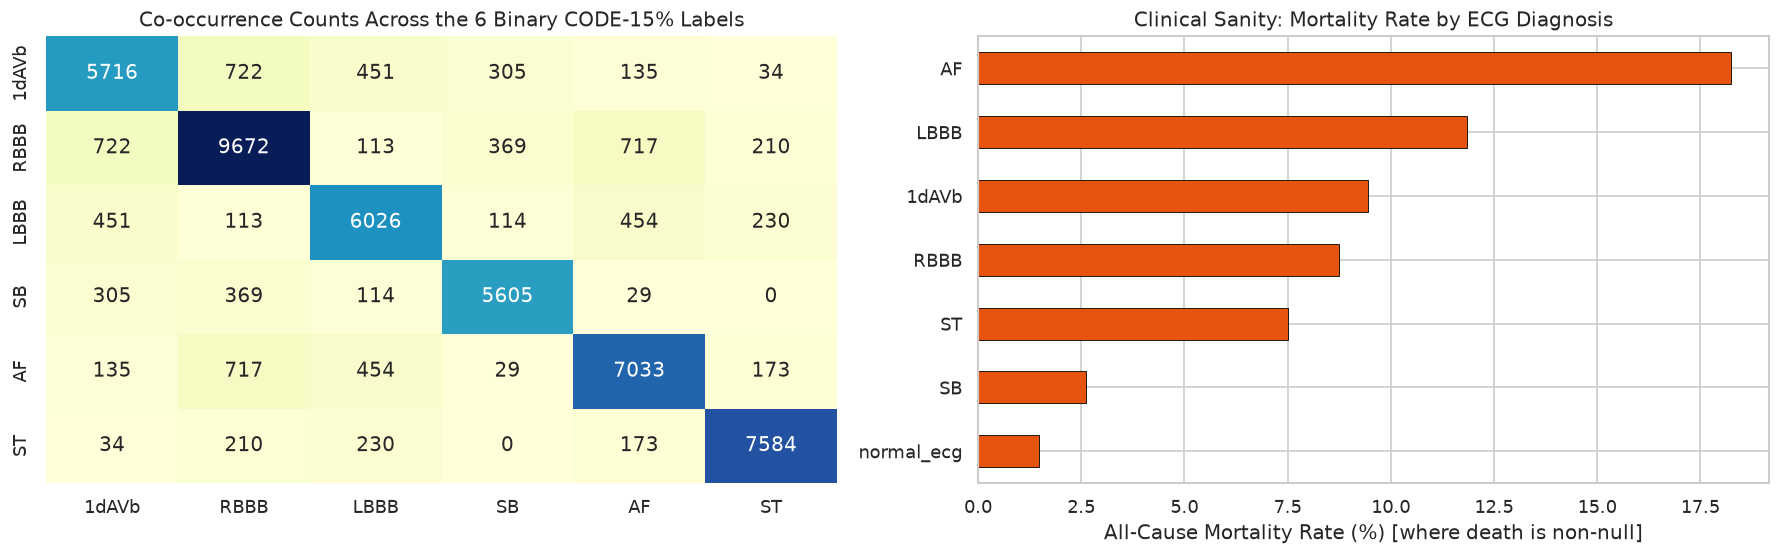

In [1]:
import sys
import warnings
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "code15" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate code15/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from code15 import CODE15Dataset

CODE15_DIR = REPO_ROOT / "code15"
DATA_DIR = CODE15_DIR / "data"
QUALITY_DIR = CODE15_DIR / "quality"
LEADS = CODE15Dataset.LEADS
LABEL_COLS = CODE15Dataset.LABEL_COLS

df = pd.read_csv(DATA_DIR / "exams.csv")
df.columns = df.columns.str.strip()

any_abn = df[LABEL_COLS].astype(bool).any(axis=1)
print("Label counts:")
for c in LABEL_COLS + ["normal_ecg"]:
    cnt = int(df[c].sum())
    print(f"  {c:<12}: {cnt:7,d} ({cnt/len(df)*100:5.2f}%)")
print(f"  Unlabeled non-normal (~normal & ~any_6): {int((~df['normal_ecg'] & ~any_abn).sum()):,} ({((~df['normal_ecg'] & ~any_abn).mean()*100):.2f}%)")

cooc = df[LABEL_COLS].astype(int).T @ df[LABEL_COLS].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.heatmap(cooc, annot=True, fmt="d", cmap="YlGnBu", ax=axes[0], cbar=False)
axes[0].set_title("Co-occurrence Counts Across the 6 Binary CODE-15% Labels")

# Mortality rate among exams with non-null 'death'
surv = df.dropna(subset=["death"]).copy()
mort_rates = {c: surv.loc[surv[c].astype(bool), "death"].mean() * 100 for c in LABEL_COLS + ["normal_ecg"]}
pd.Series(mort_rates).sort_values().plot(kind="barh", color="#e6550d", edgecolor="black", lw=0.5, ax=axes[1])
axes[1].set_xlabel("All-Cause Mortality Rate (%) [where death is non-null]")
axes[1].set_title("Clinical Sanity: Mortality Rate by ECG Diagnosis")

plt.tight_layout()
plt.show()